# Extreme Makeover: Graph Edition
**U.S. Housing & Construction Indicators, Jan 2010 - Jul 2026**

Data source: Federal Reserve Bank of St. Louis (FRED). Series: HOUST (housing starts), MORTGAGE30US (30-year fixed mortgage rate, weekly values averaged to monthly), WPU081 (PPI: lumber and wood products), TTLCONS (total construction spending).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np

df = pd.read_csv('us_housing_construction_2010_2026.csv', parse_dates=['date'])
print(df.shape)
df.head()

(199, 5)


,date,housing_starts_thousands,mortgage_rate_30yr_pct,lumber_ppi,construction_spending_millions
0,2010-01-01,614,5.03,157.2,822114
1,2010-02-01,604,4.99,166.4,814885
2,2010-03-01,636,4.97,169.2,821849
3,2010-04-01,687,5.10,175.8,829664
4,2010-05-01,583,4.89,180.0,823447


In [2]:
df.info()
df.describe().round(2)

<class 'pandas.DataFrame'>
RangeIndex: 199 entries, 0 to 198
Data columns (total 5 columns):
 #   Column                          Non-Null Count  Dtype         
---  ------                          --------------  -----         
 0   date                            199 non-null    datetime64[us]
 1   housing_starts_thousands        199 non-null    int64         
 2   mortgage_rate_30yr_pct          199 non-null    float64       
 3   lumber_ppi                      199 non-null    float64       
 4   construction_spending_millions  199 non-null    int64         
dtypes: datetime64[us](1), float64(2), int64(2)
memory usage: 7.9 KB


,date,housing_starts_thousands,mortgage_rate_30yr_pct,lumber_ppi,construction_spending_millions
count,199,199.00,199.00,199.00,199.00
mean,2018-04-01 11:34:40.402010,1171.71,4.59,232.62,1423928.84
min,2010-01-01 00:00:00,517.00,2.68,157.20,758376.00
25%,2014-02-15 00:00:00,966.00,3.69,197.50,989347.50
50%,2018-04-01 00:00:00,1226.00,4.17,215.60,1314355.00
75%,2022-05-16 12:00:00,1379.00,5.22,262.40,1916128.50
max,2026-07-01 00:00:00,1807.00,7.62,462.00,2265811.00
std,NaN,312.35,1.27,57.42,497657.82


## Visualization 1: Line plot - Lumber price index over time
Variables: `date`, `lumber_ppi`

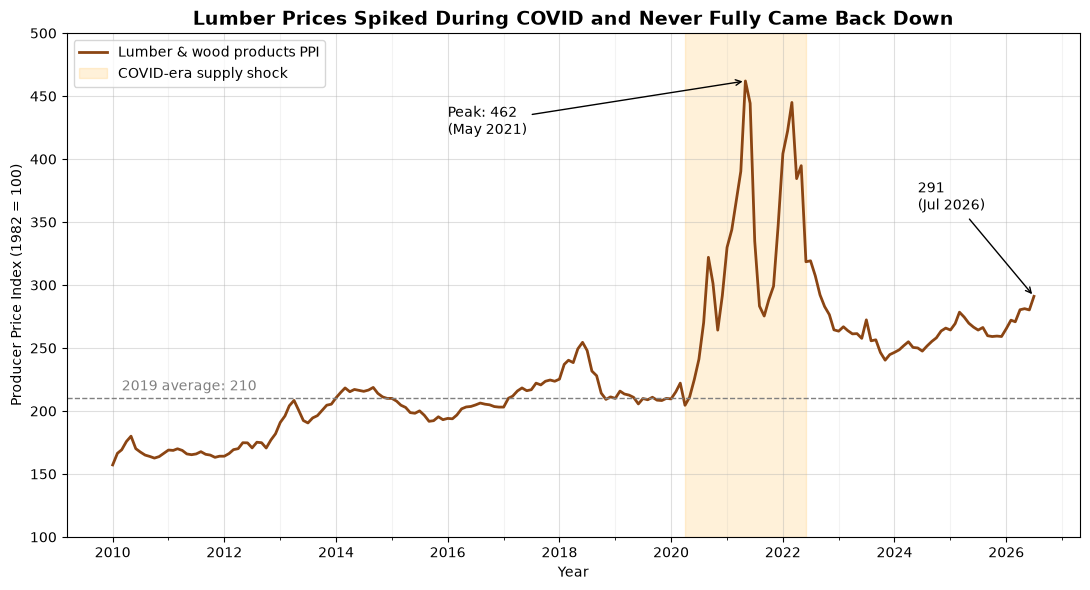

In [3]:
fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(df['date'], df['lumber_ppi'], color='saddlebrown', linewidth=2, label='Lumber & wood products PPI')

# Shade the COVID-era supply shock
ax.axvspan(pd.Timestamp('2020-04-01'), pd.Timestamp('2022-06-01'), color='orange', alpha=0.15, label='COVID-era supply shock')

# Pre-pandemic baseline (2019 average)
base = df.loc[df['date'].dt.year == 2019, 'lumber_ppi'].mean()
ax.axhline(base, color='gray', linestyle='--', linewidth=1)
ax.text(pd.Timestamp('2010-03-01'), base + 6, f'2019 average: {base:.0f}', color='gray')

# Annotate the peak
peak = df.loc[df['lumber_ppi'].idxmax()]
ax.annotate(f"Peak: {peak['lumber_ppi']:.0f}\n({peak['date']:%b %Y})",
            xy=(peak['date'], peak['lumber_ppi']),
            xytext=(pd.Timestamp('2016-01-01'), 420),
            arrowprops=dict(arrowstyle='->', color='black'), fontsize=10)

# Annotate the latest value
last = df.iloc[-1]
ax.annotate(f"{last['lumber_ppi']:.0f}\n({last['date']:%b %Y})",
            xy=(last['date'], last['lumber_ppi']), xytext=(pd.Timestamp('2024-06-01'), 360),
            arrowprops=dict(arrowstyle='->', color='black'), fontsize=10)

ax.set_title('Lumber Prices Spiked During COVID and Never Fully Came Back Down', fontsize=14, fontweight='bold')
ax.set_xlabel('Year')
ax.set_ylabel('Producer Price Index (1982 = 100)')
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_minor_locator(mdates.YearLocator(1))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.grid(which='major', alpha=0.4)
ax.grid(which='minor', alpha=0.15)
ax.set_ylim(100, 500)
ax.legend(loc='upper left')
plt.tight_layout()
plt.savefig('viz1_lumber_line.png', dpi=150)
plt.show()

## Visualization 2: Scatter plot - Mortgage rate vs. housing starts
Variables: `mortgage_rate_30yr_pct`, `housing_starts_thousands`

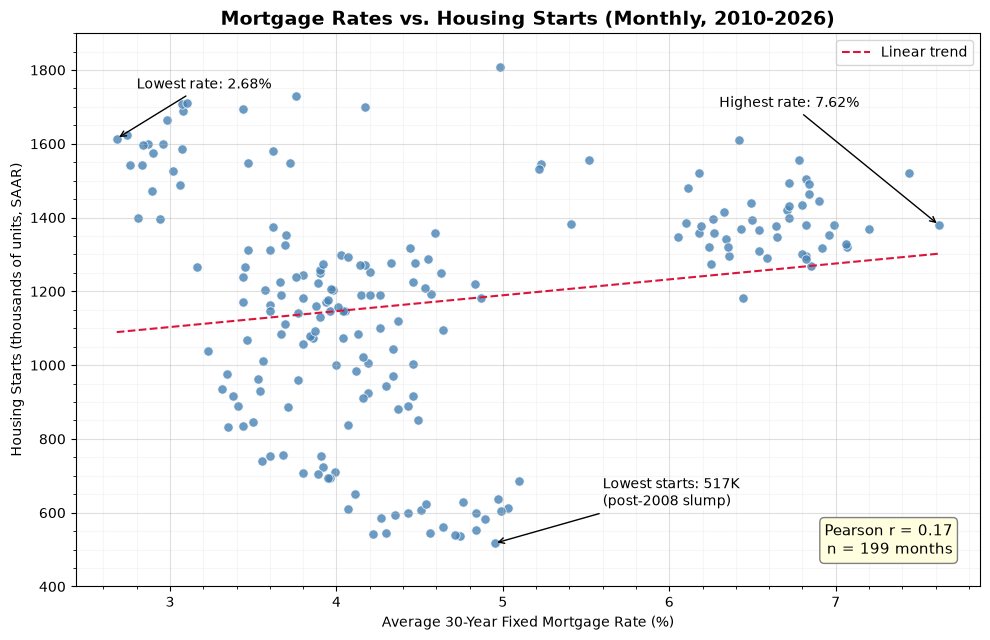

In [4]:
x = df['mortgage_rate_30yr_pct']
y = df['housing_starts_thousands']
r = x.corr(y)
m, b = np.polyfit(x, y, 1)

fig, ax = plt.subplots(figsize=(10, 6.5))
ax.scatter(x, y, s=45, c='steelblue', marker='o', edgecolors='white', linewidths=0.6, alpha=0.8)
xs = np.linspace(x.min(), x.max(), 100)
ax.plot(xs, m * xs + b, color='crimson', linestyle='--', linewidth=1.5, label='Linear trend')

# Text box with the correlation
ax.text(0.97, 0.05, f'Pearson r = {r:.2f}\nn = {len(df)} months',
        transform=ax.transAxes, ha='right', va='bottom', fontsize=11,
        bbox=dict(boxstyle='round', facecolor='lightyellow', edgecolor='gray'))

# Annotate the extremes
lo = df.loc[y.idxmin()]
ax.annotate(f"Lowest starts: {lo['housing_starts_thousands']:.0f}K\n(post-2008 slump)",
            xy=(lo['mortgage_rate_30yr_pct'], lo['housing_starts_thousands']),
            xytext=(5.6, 620), arrowprops=dict(arrowstyle='->'), fontsize=10)
hi_rate = df.loc[x.idxmax()]
ax.annotate(f"Highest rate: {hi_rate['mortgage_rate_30yr_pct']:.2f}%",
            xy=(hi_rate['mortgage_rate_30yr_pct'], hi_rate['housing_starts_thousands']),
            xytext=(6.3, 1700), arrowprops=dict(arrowstyle='->'), fontsize=10)
low_rate = df.loc[x.idxmin()]
ax.annotate(f"Lowest rate: {low_rate['mortgage_rate_30yr_pct']:.2f}%",
            xy=(low_rate['mortgage_rate_30yr_pct'], low_rate['housing_starts_thousands']),
            xytext=(2.8, 1750), arrowprops=dict(arrowstyle='->'), fontsize=10)

ax.set_title('Mortgage Rates vs. Housing Starts (Monthly, 2010-2026)', fontsize=14, fontweight='bold')
ax.set_xlabel('Average 30-Year Fixed Mortgage Rate (%)')
ax.set_ylabel('Housing Starts (thousands of units, SAAR)')
ax.set_ylim(400, 1900)
ax.minorticks_on()
ax.grid(which='major', alpha=0.4)
ax.grid(which='minor', alpha=0.1)
ax.legend(loc='upper right')
plt.tight_layout()
plt.savefig('viz2_rates_starts_scatter.png', dpi=150)
plt.show()

In [5]:
# Supporting numbers used in the write-up
print('Lumber 2019 avg:', round(base, 1), '| Peak:', peak['lumber_ppi'], peak['date'].date(), '| Latest:', last['lumber_ppi'], last['date'].date())
print('Latest vs 2019 avg: {:+.0f}%'.format((last['lumber_ppi'] / base - 1) * 100))
print('Overall correlation (rate vs starts):', round(r, 2))
for a, b2 in [('2010', '2012'), ('2022', '2026')]:
    s = df.set_index('date').loc[a:b2]
    print(a, '-', b2, 'r =', round(s['mortgage_rate_30yr_pct'].corr(s['housing_starts_thousands']), 2))

Lumber 2019 avg: 210.4 | Peak: 462.0 2021-05-01 | Latest: 291.011 2026-07-01
Latest vs 2019 avg: +38%
Overall correlation (rate vs starts): 0.17
2010 - 2012 r = -0.8
2022 - 2026 r = -0.64
